# Exploración inicial — COVID-19 (enero a junio de 2020)

Este notebook cubre el Hito 1: inspección de un reporte, nulos, estandarización, consolidación de esquemas, top 10 al 30 de junio, evolución de Chile y perfilado automático. Los reportes originales se descargan a `data/raw/` y no se versionan.

In [1]:
from datetime import date
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from descargar_reportes import descargar_reportes

RAW_DIR = ROOT / "data" / "raw" / "daily_reports"
NUEVOS = descargar_reportes(date(2020, 1, 22), date(2020, 6, 30), RAW_DIR)
print(f"Reportes nuevos descargados: {NUEVOS}; carpeta: {RAW_DIR}")

Reportes nuevos descargados: 0; carpeta: C:\Users\hecto\OneDrive\Escritorio\u\gestion de datos\Proyecto\data\raw\daily_reports


## 1. Inspección del primer reporte

Se muestran las primeras filas, dimensiones, tipos y valores nulos del archivo inicial. Los nulos deben interpretarse según el campo: por ejemplo, una provincia vacía puede indicar que el reporte está a nivel país y no necesariamente un dato perdido.

In [2]:
primer_archivo = RAW_DIR / "01-22-2020.csv"
primer_dia = pd.read_csv(primer_archivo)
display(primer_dia.head())
print(f"Filas: {len(primer_dia):,}; columnas: {len(primer_dia.columns)}")
display(primer_dia.dtypes.rename("tipo").to_frame())
nulos_primer_dia = primer_dia.isna().sum().sort_values(ascending=False)
display(nulos_primer_dia.rename("nulos").to_frame())

,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered
0,Anhui,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
1,Beijing,Mainland China,1/22/2020 17:00,14.0,NaN,NaN
2,Chongqing,Mainland China,1/22/2020 17:00,6.0,NaN,NaN
3,Fujian,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
4,Gansu,Mainland China,1/22/2020 17:00,NaN,NaN,NaN


Filas: 76; columnas: 6


,tipo
Province/State,object
Country/Region,object
Last Update,object
Confirmed,float64
Deaths,float64
Recovered,float64


,nulos
Deaths,37
Recovered,37
Province/State,12
Confirmed,10
Country/Region,0
Last Update,0


## 2. Unificación de nombres y reportes

El nombre del archivo define `report_date`. `last_update` conserva el momento en que JHU actualizó el registro y no se usa como fecha de observación. Las columnas inexistentes en una etapa quedan nulas.

In [3]:
RENOMBRAR = {
    "Province/State": "province_state", "Province_State": "province_state",
    "Country/Region": "country_region", "Country_Region": "country_region",
    "Last Update": "last_update", "Last_Update": "last_update",
    "Latitude": "lat", "Lat": "lat", "Longitude": "long", "Long_": "long",
    "Incidence_Rate": "incident_rate", "Incident_Rate": "incident_rate",
    "Case-Fatality_Ratio": "case_fatality_ratio",
    "Case_Fatality_Ratio": "case_fatality_ratio",
}

def estandarizar(df):
    df = df.rename(columns=RENOMBRAR).copy()
    df.columns = (
        df.columns.str.strip().str.lower()
        .str.replace(r"[^a-z0-9]+", "_", regex=True)
        .str.strip("_")
    )
    if "last_update" in df:
        actualizado = pd.to_datetime(df["last_update"], format="mixed", errors="coerce", utc=True)
        df["last_update"] = actualizado.dt.strftime("%Y-%m-%d")
    return df

frames = []
for archivo in sorted(RAW_DIR.glob("*.csv")):
    fecha_reporte = pd.to_datetime(archivo.stem, format="%m-%d-%Y", errors="raise")
    diario = estandarizar(pd.read_csv(archivo))
    diario["report_date"] = fecha_reporte
    frames.append(diario)

reportes = pd.concat(frames, ignore_index=True, sort=False)
reportes["report_date"] = pd.to_datetime(reportes["report_date"])
print(f"Filas consolidadas: {len(reportes):,}; columnas: {len(reportes.columns)}")
print("Columnas:", ", ".join(reportes.columns))
display(reportes.head())

Filas consolidadas: 350,945; columnas: 15
Columnas: province_state, country_region, last_update, confirmed, deaths, recovered, report_date, lat, long, fips, admin2, active, combined_key, incident_rate, case_fatality_ratio


,province_state,country_region,last_update,confirmed,deaths,recovered,report_date,lat,long,fips,admin2,active,combined_key,incident_rate,case_fatality_ratio
0,Anhui,Mainland China,2020-01-22,1.0,NaN,NaN,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Beijing,Mainland China,2020-01-22,14.0,NaN,NaN,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Chongqing,Mainland China,2020-01-22,6.0,NaN,NaN,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fujian,Mainland China,2020-01-22,1.0,NaN,NaN,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Gansu,Mainland China,2020-01-22,NaN,NaN,NaN,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Top 10 países y evolución de Chile

Los casos publicados son acumulados. Para el ranking se toma el reporte del 30 de junio y se agrupan los registros territoriales por país; la serie de Chile muestra el acumulado reportado en cada fecha.

,casos_acumulados_2020_06_30
country_region,
US,2653658.0
Brazil,1412669.0
Russia,646929.0
India,585493.0
United Kingdom,314157.0
Peru,285213.0
Chile,279393.0
Spain,249271.0
Italy,240578.0


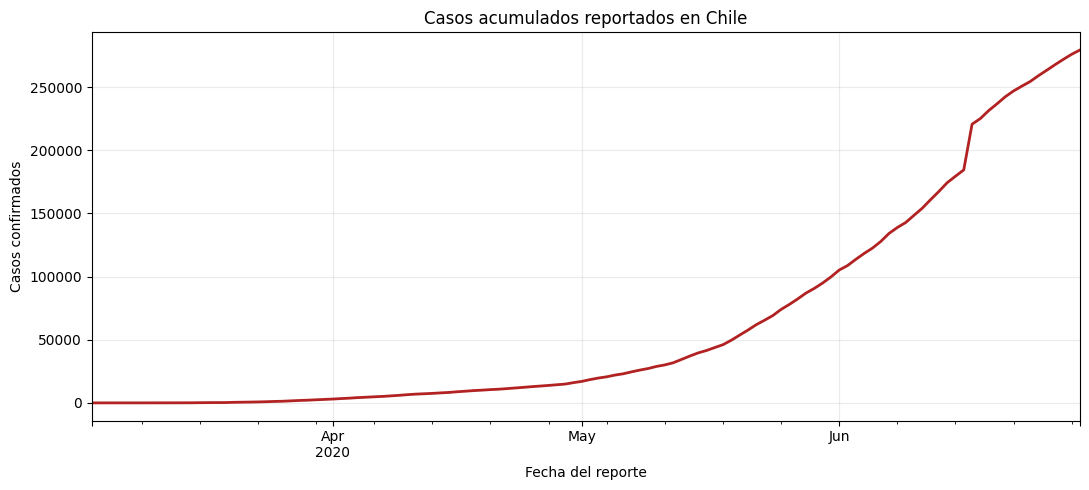

In [4]:
al_30_jun = reportes.loc[reportes["report_date"].eq(pd.Timestamp("2020-06-30"))].copy()
al_30_jun["confirmed"] = pd.to_numeric(al_30_jun["confirmed"], errors="coerce")
top10 = (al_30_jun.groupby("country_region", dropna=False)["confirmed"]
         .sum(min_count=1).sort_values(ascending=False).head(10))
display(top10.rename("casos_acumulados_2020_06_30").to_frame())

chile = reportes.loc[reportes["country_region"].eq("Chile")].copy()
chile["confirmed"] = pd.to_numeric(chile["confirmed"], errors="coerce")
serie_chile = (chile.groupby("report_date")["confirmed"].sum(min_count=1).sort_index())
ax = serie_chile.plot(figsize=(11, 5), color="firebrick", linewidth=2)
ax.set(title="Casos acumulados reportados en Chile", xlabel="Fecha del reporte", ylabel="Casos confirmados")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Perfilado automático y observaciones

El perfilado se guarda como HTML en `reports/`. Revisar el reporte y completar tres observaciones concretas antes de presentar el hito.

In [5]:
from ydata_profiling import ProfileReport

REPORTS_DIR = ROOT / "reports"
REPORTS_DIR.mkdir(exist_ok=True)
perfil = ProfileReport(reportes, title="Perfil COVID-19 — enero a junio de 2020", minimal=True)
perfil.to_file(REPORTS_DIR / "perfil_enero_junio_2020.html")
print("Perfil HTML generado:", REPORTS_DIR / "perfil_enero_junio_2020.html")

C:\Users\hecto\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\hecto\AppData\Local\Temp\ipykernel_19492\2999608391.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Summarize dataset:   0%|          | 0/20 [00:00<?, ?it/s, Describe variable: province_state]

Summarize dataset:   0%|          | 0/20 [00:00<?, ?it/s, Describe variable: country_region]

Summarize dataset:   0%|          | 0/20 [00:00<?, ?it/s, Describe variable: confirmed]     

... (37 outputs left out)

Render HTML: 100%|██████████| 1/1 [00:00<00:00,  5.20it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 136.88it/s]

Perfil HTML generado: C:\Users\hecto\OneDrive\Escritorio\u\gestion de datos\Proyecto\reports\perfil_enero_junio_2020.html


### Tres observaciones del perfil

1. El conjunto consolidado contiene **350.945 filas en 161 fechas**. La cantidad de registros diarios varía bastante (de 76 a 3.824), por lo que las comparaciones temporales deben respetar la fecha y el nivel geográfico.
2. En el primer reporte, `deaths` y `recovered` tienen **37 valores nulos de 76** y `province_state` tiene 12. En este contexto, un territorio sin provincia puede ser un dato nacional; no se debe reemplazar automáticamente por una categoría inventada ni tratar toda ausencia como error.
3. En la tabla unificada, `incident_rate` y `case_fatality_ratio` están ausentes en aproximadamente **65 %** de las filas, coherente con su incorporación posterior en el esquema. Deben conservarse como no disponibles antes de su introducción, no imputarse.